**Name:** Fredrick Kimutai 
**Student number:** 2024658 
**GitHub repository:** https://github.com/2024658/Data_Visualisation_CA1
**Video Link:** https://drive.google.com/file/d/1mhhtbhVj0GA-mRAq1ayNWuYh_EU1cvuS/view?usp=drivesdk

# US Employment in AI, Data Science and Software Development

## Project Introduction
This notebook explores the May 2023 Occupational Employment and Wage Statistics (OEWS) dataset from the US Bureau of Labor Statistics (BLS, 2023). The data is a snapshot of employment and wages by occupation, industry and location.

The purpose of the notebook is to use a range of visualisation types to show how large AI, data science and software occupations are, how well they are paid, and how this varies by place and over time. Each visualisation is explained so that we can see why that chart type fits the data.

For each of the visualisations, we explain:

1. The objective of the visualisation.
2. **Why that visualisation type was chosen** (categorical, numerical and relationship).
3. **What we have learnt** from the plot.

The BLS data has no single AI employment category, so we use eight related occupations in its place. These are:

- **AI & Data Science:** Data Scientists, Computer and Information Research Scientists, Operations Research Analysts and Statisticians
- **Software:** Software Developers and QA Analysts and Testers
- **Data Infrastructure:** Database Architects and Database Administrators

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

# Load dataset
cols = ["AREA_TITLE", "AREA_TYPE", "I_GROUP", "OCC_CODE", "OCC_TITLE", "O_GROUP", "TOT_EMP", "A_MEDIAN"]
df = pd.read_excel("all_data_M_2023.xlsx", sheet_name="All May 2023 data", usecols=cols, na_values=["*", "**", "#", "~"])
df.head()

,AREA_TITLE,AREA_TYPE,I_GROUP,OCC_CODE,OCC_TITLE,O_GROUP,TOT_EMP,A_MEDIAN
0,U.S.,1,cross-industry,00-0000,All Occupations,total,151853870.0,48060.0
1,U.S.,1,cross-industry,11-0000,Management Occupations,major,10495770.0,116880.0
2,U.S.,1,cross-industry,11-1000,Top Executives,minor,3751510.0,103460.0
3,U.S.,1,cross-industry,11-1010,Chief Executives,broad,211230.0,206680.0
4,U.S.,1,cross-industry,11-1011,Chief Executives,detailed,211230.0,206680.0


In [2]:
groups = {"15-2051": "AI & Data Science", "15-1221": "AI & Data Science",
          "15-2041": "AI & Data Science", "15-2031": "AI & Data Science",
          "15-1252": "Software", "15-1253": "Software",
          "15-1243": "Data Infrastructure", "15-1242": "Data Infrastructure"}

# National totals : U.S. rows, all industries combined, one row per occupation
us = df[(df["AREA_TITLE"] == "U.S.") & (df["I_GROUP"] == "cross-industry")]
nat = us[(us["O_GROUP"] == "detailed") & (us["OCC_CODE"].isin(groups))].copy()
nat["group"] = nat["OCC_CODE"].map(groups)

# Benchmark: median salary of ALL US jobs
us_median = us[us["O_GROUP"] == "total"]["A_MEDIAN"].iloc[0]
print("Median salary of all US jobs:", us_median)
nat[["OCC_TITLE", "TOT_EMP", "A_MEDIAN", "group"]]

Median salary of all US jobs: 48060.0


,OCC_TITLE,TOT_EMP,A_MEDIAN,group
138,Computer and Information Research Scientists,35210.0,145080.0,AI & Data Science
144,Database Administrators,76140.0,101510.0,Data Infrastructure
145,Database Architects,59920.0,134700.0,Data Infrastructure
149,Software Developers,1656880.0,132270.0,Software
150,Software Quality Assurance Analysts and Testers,203040.0,101800.0,Software
161,Operations Research Analysts,117880.0,83640.0,AI & Data Science
163,Statisticians,29950.0,104110.0,AI & Data Science
165,Data Scientists,192710.0,108020.0,AI & Data Science


# 1. Horizontal Bar Chart - Employment by Occupation

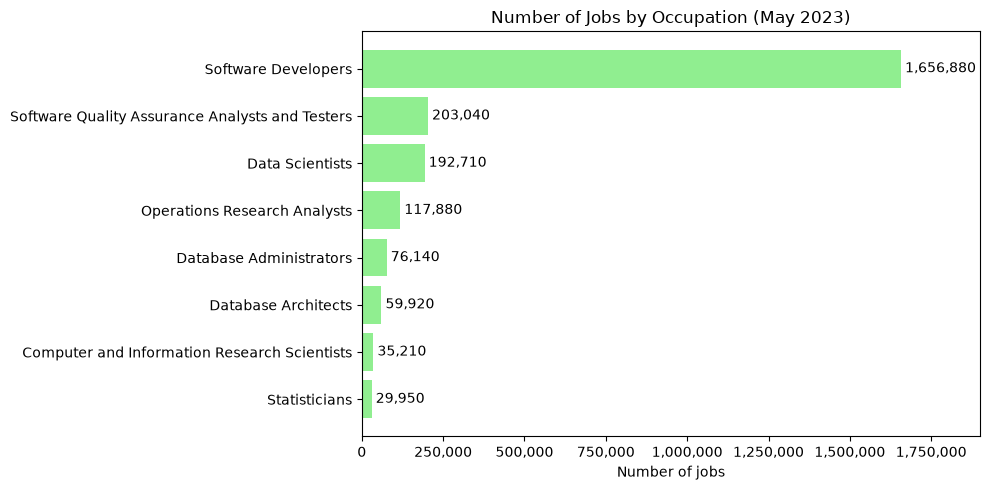

In [3]:
emp = nat.sort_values("TOT_EMP")

plt.figure(figsize=(10, 5))
bars = plt.barh(emp["OCC_TITLE"], emp["TOT_EMP"], color="lightgreen")
plt.bar_label(bars, fmt="{:,.0f}", padding=3)
plt.gca().xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
plt.xlim(0, 1_900_000)
plt.title("Number of Jobs by Occupation (May 2023)")
plt.xlabel("Number of jobs")
plt.tight_layout()
plt.show()

- **Objective:** To compare how many people work in each of our eight occupations, to see how big AI and data roles are next to software roles.
- **Why this plot:** Horizontal bars suit long category labels like occupation names, and sorting the bars shows the rank better.
- **Learning:** AI related jobs are less  compared with general software work. Software Developers dominate with about 1.66 million jobs, roughly eight times the next largest (QA Analysts and Testers, 203,040). Data Scientists have 192,710 jobs and Statisticians only 29,950.

# 2.Bar chart - Median Salary by Occupations

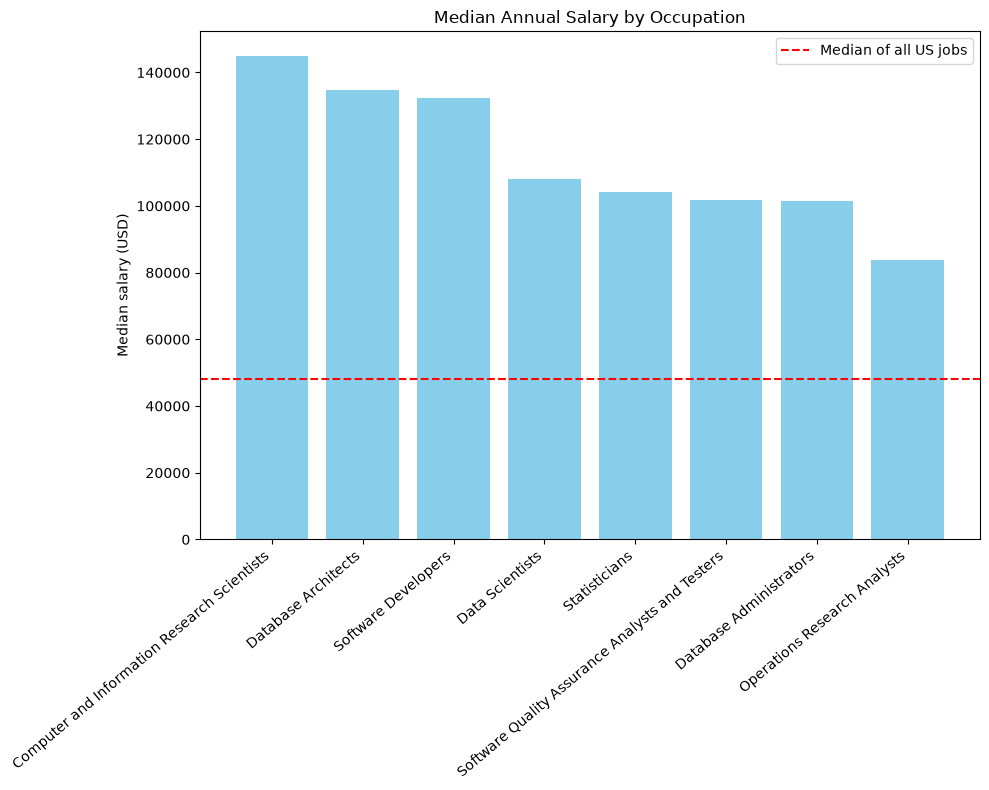

In [4]:
pay = nat.sort_values("A_MEDIAN", ascending=False)

plt.figure(figsize=(10, 8))
plt.bar(pay["OCC_TITLE"], pay["A_MEDIAN"], color="skyblue")
plt.axhline(us_median, color="red", linestyle="--", label="Median of all US jobs")
plt.xticks(rotation=40, ha="right")
plt.title("Median Annual Salary by Occupation")
plt.ylabel("Median salary (USD)")
plt.bar_label(bars, fmt="${:,.0f}", padding=3, fontsize=8)
plt.legend()
plt.tight_layout()
plt.show()

- **Objective:** Compare typical pay across the eight occupations and against the normal US worker.
- **Why this plot:** Bar charts compare one numeric value across a small number of categories, and the dashed line adds a benchmark for context.
- **Learning:** Computer and Information Research Scientists earn the most, about three times the US median of $48,060 and Operations Research Analysts the least. and Data Scientists earn less than Software Developers.

# 3. Pie Chart – Share of Jobs by Role Group

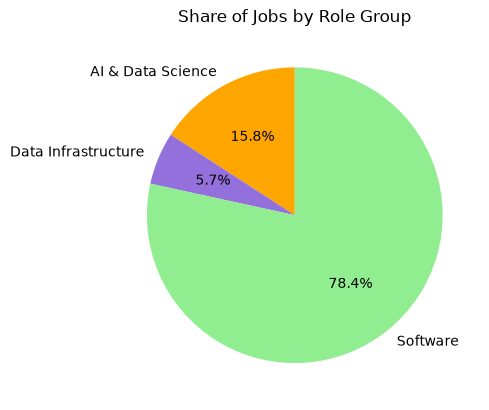

In [5]:
share = nat.groupby("group")["TOT_EMP"].sum()

plt.pie(share, labels=share.index, autopct="%1.1f%%", startangle=90, colors=["orange", "mediumpurple", "lightgreen"])
plt.title("Share of Jobs by Role Group")
plt.show()

- **Objective:** Show how the jobs in the eight occupations divide between the three role groups.
- **Why this plot:** Pie charts are good for whole-part relationships when there are only a few slices that add up to 100%.
- **Learning:** Software makes a majority of these jobs at 78%, AI & Data Science  and Data Infrastructure follow at about 16% and 6% respectively .

# 4. Scatterplot - Number of Jobs vs Median Salary

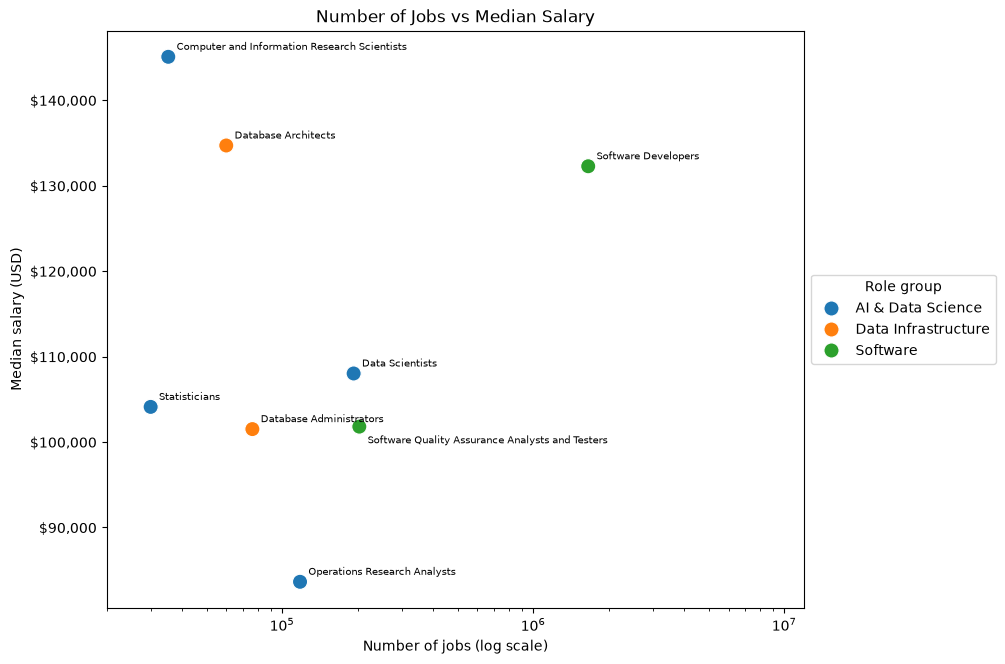

In [6]:
plt.figure(figsize=(9, 7.5))
sns.scatterplot(x="TOT_EMP", y="A_MEDIAN", hue="group", data=nat, s=120)
for _, r in nat.iterrows():
    plt.annotate(r["OCC_TITLE"], (r["TOT_EMP"], r["A_MEDIAN"]), xytext=(6, -12) if "Quality" in r["OCC_TITLE"] else (6, 5), textcoords="offset points", fontsize=7)
plt.xscale("log")
plt.xlim(2e4, 1.2e7)
plt.gca().yaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
plt.title("Number of Jobs vs Median Salary")
plt.xlabel("Number of jobs (log scale)")
plt.ylabel("Median salary (USD)")
plt.legend(title="Role group", loc="center left", bbox_to_anchor=(1, 0.5))
plt.show()

- **Objective:** See whether occupations with more jobs also pay more, and how the three role groups compare.
- **Why this plot:** Scatterplots reveal patterns between two numeric variables, and colour shows the role group.
- **Learning:** There is no clear pattern between jobs and pay. Software has the most jobs (about 1.66 million) but not the highest pay, and AI & Data Science covers the widest range of pay about 84,000 USD to 145,000 USD.

# 5 . Boxplot - Salary Across US states

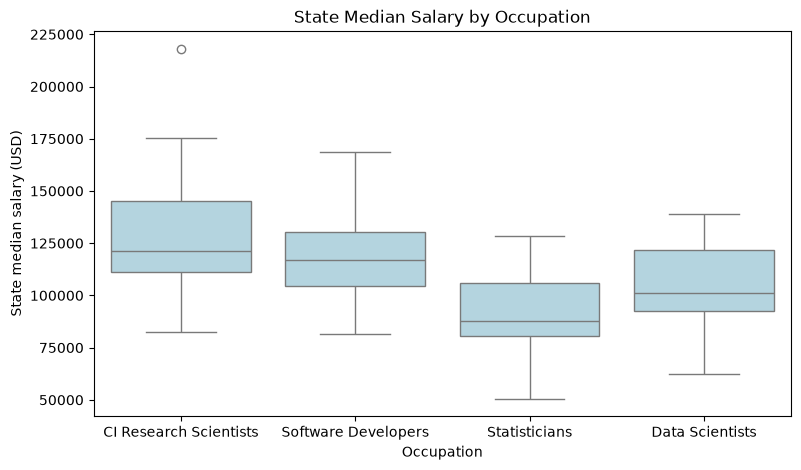

In [7]:
four = ["15-2051", "15-1221", "15-2041", "15-1252"]
states = df[(df["AREA_TYPE"] == 2) & (df["I_GROUP"] == "cross-industry") & (df["OCC_CODE"].isin(four))].copy()
states["OCC_TITLE"] = states["OCC_TITLE"].replace("Computer and Information Research Scientists", "CI Research Scientists")

plt.figure(figsize=(9, 5))
sns.boxplot(x="OCC_TITLE", y="A_MEDIAN", data=states, color="lightblue")
plt.title("State Median Salary by Occupation")
plt.xlabel("Occupation")
plt.ylabel("State median salary (USD)")

plt.show()


In [10]:
states.groupby("OCC_TITLE")["A_MEDIAN"].agg(["min", "median", "max"])

,min,median,max
OCC_TITLE,,,
CI Research Scientists,82360.0,121060.0,218180.0
Data Scientists,62600.0,100950.0,138780.0
Software Developers,81380.0,116830.0,168660.0
Statisticians,50620.0,87920.0,128640.0


- **Objective:** Compare how each occupation’s median salary changes from state to state.
- **Why this plot:** Boxplots make it easy to compare typical salaries, see how spread out they are, and spot states with unusually high or low salaries.
- **Learning:** Computer and Information Research Scientists have the highest typical state salary at around 121,000 USD, while Statisticians have the lowest at about 88,000 USD. CI Research Scientists also show the biggest differences between states, with salaries ranging from roughly 82,000 USD to 175,000 USD, plus one outlier at around 218,000 USD. For Data Scientists and Statisticians, the difference between the lowest and highest state salaries is about 76,000 - 78,000 USD. The exact figures are in the table below the chart.

# 6. Histogram – Data Scientist Salary Across Metro Areas

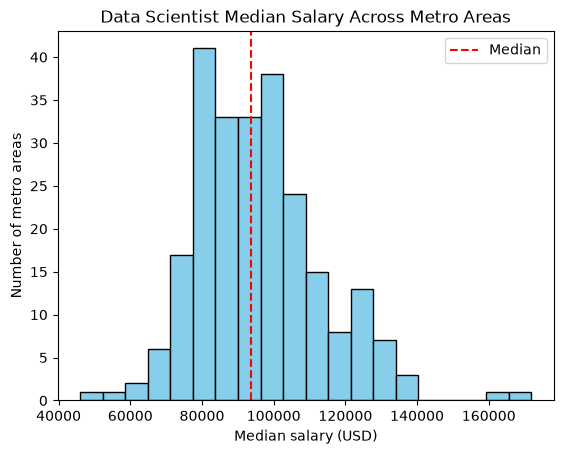

Metro areas: 244
Median: 93550.0


,AREA_TITLE,A_MEDIAN
238744,"San Jose-Sunnyvale-Santa Clara, CA",171800.0
238743,"San Francisco-Oakland-Hayward, CA",163430.0
238791,"Bridgeport-Stamford-Norwalk, CT",137420.0


In [8]:
# fitering metro areas only all industries combined just data scientists.
metro = df[(df["AREA_TYPE"] == 4) & (df["I_GROUP"] == "cross-industry") & (df["OCC_CODE"] == "15-2051")]

plt.hist(metro["A_MEDIAN"].dropna(), bins=20, color="skyblue", edgecolor="black")
plt.title("Data Scientist Median Salary Across Metro Areas")
plt.axvline(metro["A_MEDIAN"].median(), color="red", linestyle="--", label="Median")
plt.xlabel("Median salary (USD)")
plt.ylabel("Number of metro areas")
plt.legend()
plt.show()

print("Metro areas:", metro["A_MEDIAN"].count())
print("Median:", metro["A_MEDIAN"].median())
metro.nlargest(3, "A_MEDIAN")[["AREA_TITLE", "A_MEDIAN"]]


- **Objective:** Investigate how median Data Scientist salaries vary across US metropolitan areas.
- **Why this plot:** Salary is numerical, and a histogram groups the values into ranges so we can see which ranges are most common and how widely salaries vary.
- **Learning:** Many metro areas have median salaries between roughly 78,000 and 110,000 USD, with a typical value of about 93,550 USD across 244 areas. The distribution is skewed to the right, showing that a few areas pay much more than most. This suggests that location matters when comparing pay for Data Scientist roles. The table below the chart identifies San Jose (171,800 USD) and San Francisco (163,430 USD) as the highest-paying areas. These figures compare median salaries across areas, rather than individual workers' salaries.

# Challenge – Employment and Pay Over Time

The BLS publishes all data file dataset file for each year on its website. Using the May 2023 data already loaded above, this section adds the 2021, 2022, 2024 and 2025 files to compare employment and median salary trends from 2021 to 2025.

Occupation,All US jobs,CI Research Scientists,Data Scientists,Software Developers,Statisticians
year,,,,,
2021,140886310.0,30840.0,105980.0,1364180.0,31370.0
2022,147886000.0,33780.0,159630.0,1534790.0,30780.0
2023,151853870.0,35210.0,192710.0,1656880.0,29950.0
2024,154187380.0,38480.0,233440.0,1654440.0,29800.0
2025,155495730.0,37200.0,262440.0,1687890.0,29030.0


Occupation,All US jobs,CI Research Scientists,Data Scientists,Software Developers,Statisticians
year,,,,,
2021,45760.0,131490.0,100910.0,120730.0,95570.0
2022,46310.0,136620.0,103500.0,127260.0,98920.0
2023,48060.0,145080.0,108020.0,132270.0,104110.0
2024,49500.0,140910.0,112590.0,133080.0,103300.0
2025,50980.0,140300.0,120230.0,135980.0,105650.0


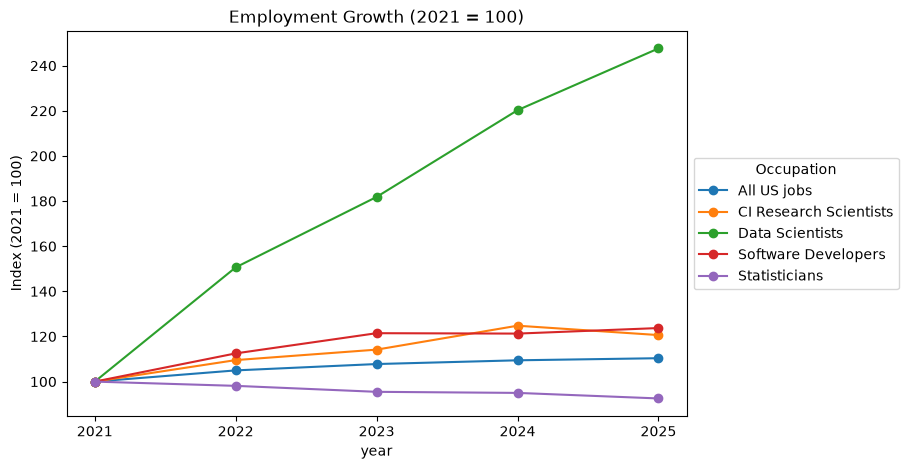

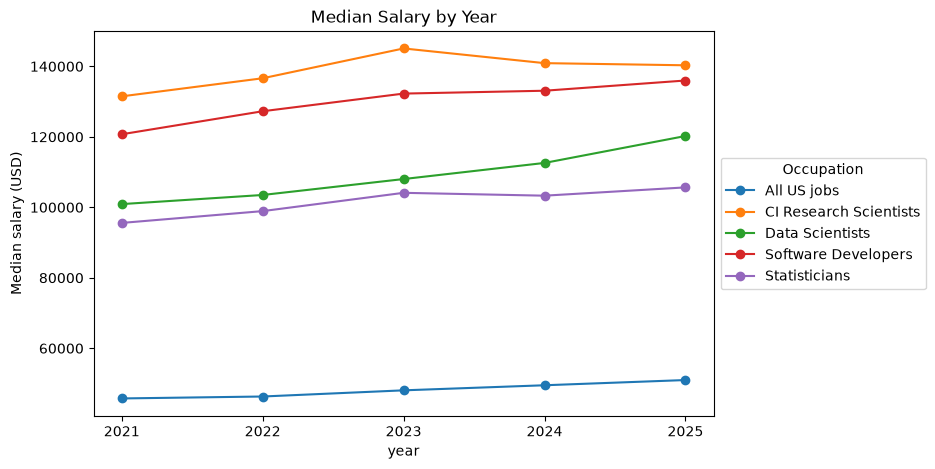

,Jobs change %,Salary change %
Occupation,,
All US jobs,10.4,11.4
CI Research Scientists,20.6,6.7
Data Scientists,147.6,19.1
Software Developers,23.7,12.6
Statisticians,-7.5,10.5


In [9]:
years = [2021, 2022, 2023, 2024, 2025]
focus = {"15-2051": "Data Scientists", "15-1221": "CI Research Scientists",
         "15-2041": "Statisticians", "15-1252": "Software Developers", "00-0000": "All US jobs"}
use = ["AREA_TITLE", "I_GROUP", "OCC_CODE", "TOT_EMP", "A_MEDIAN"]


frames = []
for y in years:
    if y == 2023:
        data = df
    else:
        data = pd.read_excel(f"all_data_M_{y}.xlsx", usecols=use, na_values=["*", "**", "#", "~"])
       
    data = data[(data["AREA_TITLE"] == "U.S.") & (data["I_GROUP"] == "cross-industry") & (data["OCC_CODE"].isin(focus))].copy()
    data["year"] = y
    frames.append(data)

trend = pd.concat(frames)
trend["Occupation"] = trend["OCC_CODE"].map(focus)

# Tables by year (jobs_index: 2021 = 100 so different sizes can be compared)
jobs = trend.pivot(index="year", columns="Occupation", values="TOT_EMP")
pay = trend.pivot(index="year", columns="Occupation", values="A_MEDIAN")
jobs_index = jobs / jobs.iloc[0] * 100
display(jobs)
display(pay)

# Employment chart
jobs_index.plot(marker="o", figsize=(8, 5))
plt.title("Employment Growth (2021 = 100)")
plt.ylabel("Index (2021 = 100)")
plt.xticks(jobs.index)
plt.legend(title="Occupation", loc="center left", bbox_to_anchor=(1, 0.5))
plt.show()

# Salary chart
pay.plot(marker="o", figsize=(8, 5))
plt.title("Median Salary by Year")
plt.ylabel("Median salary (USD)")
plt.xticks(pay.index)
plt.legend(title="Occupation", loc="center left", bbox_to_anchor=(1, 0.5))
plt.show()

# Change from 2021 to 2025
summary = pd.DataFrame({"Jobs change %": (jobs.iloc[-1] / jobs.iloc[0] - 1) * 100,
                        "Salary change %": (pay.iloc[-1] / pay.iloc[0] - 1) * 100}).round(1)
summary

- **Objective:** Compare how employment and median salaries changed for four AI-related occupations between 2021 and 2025, using all US jobs as a benchmark.
- **Why this plot:** Line charts make it easy to follow changes over time. The employment chart starts every occupation at 100 in 2021, so we can compare their percentage growth even though they have different numbers of workers. The salary chart compares median annual pay in USD.
- **Learning:** Data Scientists had the largest employment increase, rising from 105,980 to 262,440 jobs about 148%. Software Developers grew by 24% and Computer and Information Research Scientists by 21%, compared with 10% for all US jobs. Statisticians were the only selected occupation to decline, falling by 7.5%. Data Scientists also had the largest percentage increase in median pay among the four occupations, rising by about 19%, from 100,910 to 120,230 USD. This compares with 11% for all US jobs. These figures are survey estimates, and salaries are not adjusted for inflation, so higher pay does not necessarily mean the same increase in buying power.

## References

BLS (2021) *Occupational Employment and Wage Statistics: May 2021 Estimates*. US Bureau of Labor Statistics. Available at: https://www.bls.gov/oes/tables.htm (Accessed: 5 November 2026).

BLS (2022) *Occupational Employment and Wage Statistics: May 2022 Estimates*. US Bureau of Labor Statistics. Available at: https://www.bls.gov/oes/tables.htm (Accessed: 5 November 2026).

BLS (2023) *Occupational Employment and Wage Statistics: May 2023 National, State, Metropolitan, and Nonmetropolitan Area Occupational Employment and Wage Estimates*. US Bureau of Labor Statistics. Available at: https://www.bls.gov/oes/tables.htm (Accessed: 5 November 2026).

BLS (2024) *Occupational Employment and Wage Statistics: May 2024 Estimates*. US Bureau of Labor Statistics. Available at: https://www.bls.gov/oes/tables.htm (Accessed: 5 November 2026).

BLS (2025) *Occupational Employment and Wage Statistics: May 2025 Estimates*. US Bureau of Labor Statistics. Available at: https://www.bls.gov/oes/tables.htm (Accessed: 5 November 2026).


OpenAI (2026) *ChatGPT* [Large language model]. Available at: https://chat.openai.com (Accessed:3rd November).

Project Jupyter (n.d.) *Jupyter Notebook documentation*. Available at: https://jupyter-notebook.readthedocs.io/ (Accessed: 3 November 2026).

Waskom, M.L. (2024) *seaborn: statistical data visualization, version 0.13.2 documentation*. Available at: https://seaborn.pydata.org/ (Accessed: 3 November 2026).